# Analysis of Unstructured Data: Problem Set 1

**Vector representations, similarity & dimensionality reduction**

Theory answers (Problems 1–4) and the written analysis (Problem 8) are in Markdown cells. All numbers and figures are reproduced by running the notebook top to bottom.

Extra dependency: `umap-learn`. Problem 5 downloads one short WAV file, so it needs an internet connection.

In [ ]:
import re
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np
import pandas as pd
import sklearn
import umap
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from scipy.io import wavfile
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
from sklearn.datasets import load_digits, load_sample_image
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness

SEED = 42

SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948",
)

# Ten classes exceed the eight distinguishable hues, so digits 8 and 9 reuse the hue of a
# distant class with a different marker; every cluster is also labelled directly.
CLASS_STYLE = {
    0: (BLUE, "o"), 1: (ORANGE, "o"), 2: (AQUA, "o"), 3: (YELLOW, "o"), 4: (MAGENTA, "o"),
    5: (GREEN, "o"), 6: (VIOLET, "o"), 7: (RED, "o"), 8: (BLUE, "^"), 9: (VIOLET, "^"),
}

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.edgecolor": GRID, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.6,
    "legend.frameon": False,
})


def scatter_by_class(ax, Z, y, title, ticks=True):
    for digit, (color, marker) in CLASS_STYLE.items():
        pts = Z[y == digit]
        ax.scatter(pts[:, 0], pts[:, 1], s=13, c=color, marker=marker, alpha=0.75,
                   linewidths=0.25, edgecolors=SURFACE, rasterized=True)
    for digit in CLASS_STYLE:
        cx, cy = np.median(Z[y == digit], axis=0)
        ax.text(cx, cy, str(digit), ha="center", va="center", fontsize=12, fontweight="bold", color=INK,
                path_effects=[pe.withStroke(linewidth=3, foreground=SURFACE)])
    ax.set_title(title, loc="left")
    if not ticks:
        ax.set_xticks([])
        ax.set_yticks([])


def class_handles():
    return [Line2D([], [], linestyle="", color=c, marker=m, markersize=7, label=str(d))
            for d, (c, m) in CLASS_STYLE.items()]

## Problem 1 [Theory]: Euclidean vs cosine geometry on the unit sphere

**Assumptions.** $\langle\cdot,\cdot\rangle$ is a real inner product on $\mathbb{R}^d$: it is bilinear, symmetric ($\langle x,y\rangle=\langle y,x\rangle$) and positive definite. The norm and the distance it induces are

$$
\lVert x\rVert = \sqrt{\langle x,x\rangle}, \qquad d(x,y) = \lVert x-y\rVert .
$$


For non-zero $x,y$ the cosine similarity is

$$
\cos\theta = \frac{\langle x,y\rangle}{\lVert x\rVert\,\lVert y\rVert}.
$$

The Cauchy–Schwarz inequality $|\langle x,y\rangle|\le\lVert x\rVert\,\lVert y\rVert$ holds in every inner product space, so $\cos\theta\in[-1,1]$ and the angle $\theta=\arccos(\cos\theta)\in[0,\pi]$ is well defined. If $\lVert x\rVert=\lVert y\rVert=1$, the definition reduces to $\cos\theta=\langle x,y\rangle$.

$$
\begin{aligned}
\lVert x-y\rVert^2 &= \langle x-y,\,x-y\rangle \\
&= \langle x,x\rangle - \langle x,y\rangle - \langle y,x\rangle + \langle y,y\rangle \\
&= \lVert x\rVert^2 - 2\langle x,y\rangle + \lVert y\rVert^2 \\
&= 1 - 2\cos\theta + 1 = 2(1-\cos\theta). \qquad\blacksquare
\end{aligned}
$$

The norm and the cosine must come from the *same* inner product.

*Remark (complex case).* If the inner product is complex, conjugate symmetry gives $\langle x,y\rangle+\langle y,x\rangle = 2\,\mathrm{Re}\,\langle x,y\rangle$. The identity then holds with $\cos\theta := \mathrm{Re}\,\langle x,y\rangle/(\lVert x\rVert\,\lVert y\rVert)$.

**Same ranking of neighbours.** Work on the unit sphere $S=\{x:\lVert x\rVert=1\}$ of this norm. Fix a query $q\in S$ and candidates $x_1,\dots,x_n\in S$, and let $c_i = \langle q,x_i\rangle \in [-1,1]$. By the identity,

$$
\lVert q-x_i\rVert = g(c_i), \qquad g(c) = \sqrt{2(1-c)}.
$$

The map $g$ is strictly decreasing on $[-1,1]$, so for all $i,j$

$$
\lVert q-x_i\rVert \le \lVert q-x_j\rVert \iff c_i \ge c_j,
$$

and equality holds on one side exactly when it holds on the other. Sorting by increasing distance and sorting by decreasing cosine similarity therefore give the same order, ties included, so the $k$ nearest neighbours coincide for every $k$.

## Problem 2 [Theory]: Cosine distance is not a metric

**Setting.** As in Problem 1, $\langle\cdot,\cdot\rangle$ is a real inner product on $\mathbb{R}^d$ with $\lVert x\rVert=\sqrt{\langle x,x\rangle}$ and $\cos(x,y)=\langle x,y\rangle/(\lVert x\rVert\,\lVert y\rVert)$. The counterexample only needs one concrete case, so it uses $\mathbb{R}^2$ with the standard dot product. The proof that angular distance is a metric holds for every $d$ and every inner product.

**Counterexample.** In $\mathbb{R}^2$ take

$$
x = (1,0),\qquad y = \tfrac{1}{\sqrt 2}(1,1),\qquad z = (0,1).
$$

Then $\cos(x,y) = \cos(y,z) = \tfrac{1}{\sqrt2}$ and $\cos(x,z) = 0$, so

$$
d_{\cos}(x,y) + d_{\cos}(y,z) = 2\left(1-\tfrac{1}{\sqrt2}\right) = 2-\sqrt 2 \approx 0.586 \;<\; 1 = d_{\cos}(x,z).
$$

The triangle inequality is violated, so $d_{\cos}$ is not a metric. (Also, $d_{\cos}(x,2x)=0$ with $x\neq 2x$, so positive-definiteness fails on $\mathbb{R}^d\setminus\{0\}$.)

The reason follows from Problem 1: on the unit sphere $d_{\cos}(x,y)=\tfrac12\lVert x-y\rVert_2^2$. It behaves like a *squared* distance, about $\theta^2/2$ for small angles, and squares of a metric need not satisfy the triangle inequality.

**Angular distance.** Let $d_\angle(x,y) = \arccos(\cos(x,y))/\pi = \theta(x,y)/\pi \in [0,1]$. On the same three points,

$$
d_\angle(x,y)+d_\angle(y,z) = \tfrac14+\tfrac14 = \tfrac12 = d_\angle(x,z),
$$

so the inequality holds, here with equality, since $y$ lies on the arc between $x$ and $z$.

**Triangle inequality in general.** Let $u,v,w\in\mathbb{R}^d$ with $\lVert u\rVert=\lVert v\rVert=\lVert w\rVert=1$, where $d\ge1$ is arbitrary. Define

$$
\alpha=\theta(u,v)=\arccos\langle u,v\rangle,\qquad \beta=\theta(v,w)=\arccos\langle v,w\rangle,\qquad \alpha,\beta\in[0,\pi].
$$

We must show $\theta(u,w)\le\alpha+\beta$.

*Step 1: decompose $u$ along $v$.* This is the orthogonal decomposition behind Gram–Schmidt. Split $u$ into its projection onto $v$ and a remainder:

$$
u = \langle u,v\rangle\, v + r, \qquad r := u - \langle u,v\rangle\, v .
$$

Because $\lVert v\rVert=1$, the projection coefficient is $\langle u,v\rangle=\cos\alpha$, so $r=u-\cos\alpha\,v$.

- **$r$ is orthogonal to $v$.** By linearity,
  $$\langle r,v\rangle=\langle u,v\rangle-\cos\alpha\,\langle v,v\rangle=\cos\alpha-\cos\alpha\cdot1=0.$$
- **$r$ has length $\sin\alpha$.** By bilinearity and symmetry,
  $$
  \lVert r\rVert^2=\langle u-\cos\alpha\,v,\;u-\cos\alpha\,v\rangle
  =\langle u,u\rangle-2\cos\alpha\,\langle u,v\rangle+\cos^2\alpha\,\langle v,v\rangle
  =1-2\cos^2\alpha+\cos^2\alpha=1-\cos^2\alpha=\sin^2\alpha .
  $$
  Since $\alpha\in[0,\pi]$, $\sin\alpha\ge0$, hence $\lVert r\rVert=\sin\alpha$.

Now define the unit direction of the remainder:

$$
a:=\begin{cases} r/\sin\alpha, & \sin\alpha>0,\\ 0, & \sin\alpha=0 \ \ (\text{then } r=0,\ u=\pm v).\end{cases}
$$

In both cases $r=\sin\alpha\,a$, $\langle a,v\rangle=0$ and $\lVert a\rVert\le1$. Substituting into $u=\cos\alpha\,v+r$ gives the first identity:

$$
u=\cos\alpha\,v+\sin\alpha\,a .
$$

So $u$ is written in "polar coordinates" in the plane spanned by $v$ and $a$: $\cos\alpha$ is its component along $v$ and $\sin\alpha$ its component perpendicular to $v$.

*Step 2: decompose $w$ in the same way.* Applying the same argument with $\beta=\arccos\langle v,w\rangle$ gives

$$
w=\cos\beta\,v+\sin\beta\,b,\qquad \langle b,v\rangle=0,\quad \lVert b\rVert\le1 .
$$

*Step 3: compute $\langle u,w\rangle$.* By bilinearity, using $\langle v,v\rangle=1$ and $\langle v,b\rangle=\langle a,v\rangle=0$,

$$
\begin{aligned}
\langle u,w\rangle&=\cos\alpha\cos\beta\,\langle v,v\rangle+\cos\alpha\sin\beta\,\langle v,b\rangle+\sin\alpha\cos\beta\,\langle a,v\rangle+\sin\alpha\sin\beta\,\langle a,b\rangle\\
&=\cos\alpha\cos\beta+\sin\alpha\sin\beta\,\langle a,b\rangle .
\end{aligned}
$$

*Step 4: bound it.* Cauchy–Schwarz gives $\langle a,b\rangle\ge-\lVert a\rVert\,\lVert b\rVert\ge-1$. Since $\sin\alpha\sin\beta\ge0$,

$$
\langle u,w\rangle\ \ge\ \cos\alpha\cos\beta-\sin\alpha\sin\beta=\cos(\alpha+\beta).
$$

*Step 5: convert to angles.* If $\alpha+\beta\le\pi$, then $\alpha+\beta$ lies in $[0,\pi]$, where $\arccos$ is decreasing and inverts $\cos$:

$$
\theta(u,w)=\arccos\langle u,w\rangle\le\arccos\big(\cos(\alpha+\beta)\big)=\alpha+\beta .
$$

If $\alpha+\beta>\pi$, the bound is immediate because $\theta(u,w)\le\pi$. Dividing by $\pi$ gives $d_\angle(u,w)\le d_\angle(u,v)+d_\angle(v,w)$.

The proof never uses coordinates or the value of $d$. It uses only bilinearity, symmetry, Cauchy–Schwarz and the norm $\sqrt{\langle x,x\rangle}$, so it holds in every real inner product space.

**The other metric axioms.** $d_\angle$ is non-negative, and it is symmetric because $\langle u,v\rangle=\langle v,u\rangle$. On the unit sphere, $\theta(u,v)=0 \iff \langle u,v\rangle=1 \iff \lVert u-v\rVert^2=2-2\langle u,v\rangle=0 \iff u=v$, using Problem 1. Hence $d_\angle$ is a true metric on the unit sphere, equal to the geodesic (great-circle) distance divided by $\pi$. For non-zero vectors it is defined through their normalisations, $d_\angle(x,y)=d_\angle(x/\lVert x\rVert,\,y/\lVert y\rVert)$. On $\mathbb{R}^d\setminus\{0\}$ it is therefore only a pseudometric, because vectors on the same ray are at distance 0.

## Problem 3 [Theory]: Curse of dimensionality

### Distance concentration

**Assumptions.** $n$ is fixed. $X_1,\dots,X_n$ are i.i.d. uniform on $[0,1]^d$ with independent coordinates. The query $q\in[0,1]^d$ is fixed (not random), and $D_i=\lVert X_i-q\rVert_2$.

Write $D_i^2=\sum_{j=1}^d (X_{ij}-q_j)^2$. This is a sum of $d$ independent terms in $[0,1]$. Each term has mean

$$
\mu_j = \mathbb{E}(U-q_j)^2 = \tfrac{1}{12}+\left(q_j-\tfrac12\right)^2\in\left[\tfrac1{12},\tfrac13\right],
$$

so $S_d:=\mathbb{E}D_i^2=\sum_j\mu_j\ge d/12$. For $\varepsilon\in(0,1)$, Hoeffding's inequality with $t=\varepsilon S_d\ge\varepsilon d/12$ gives

$$
\mathbb{P}\left(\left|D_i^2-S_d\right|\ge \varepsilon S_d\right)\le 2\exp\left(-\frac{2t^2}{d}\right)\le 2\exp\left(-\frac{\varepsilon^2 d}{72}\right).
$$

**From one point to all $n$ points (union bound).** $D_{\min}$ and $D_{\max}$ are the distances of two of the points, but we do not know in advance which ones, so all $n$ points must be controlled simultaneously. Let

$$
A_i=\left\{\left|D_i^2-S_d\right|\ge\varepsilon S_d\right\},\qquad i=1,\dots,n,
$$

be the "bad" event for point $i$. Each satisfies $\mathbb{P}(A_i)\le 2e^{-\varepsilon^2 d/72}$ by the bound above. Boole's inequality, $\mathbb{P}\left(\bigcup_i A_i\right)\le\sum_i\mathbb{P}(A_i)$, does not need the events to be independent, and gives

$$
\mathbb{P}\Big(\bigcup_{i=1}^n A_i\Big)\le 2n\,e^{-\varepsilon^2 d/72}.
$$

On the complementary event, which has probability at least $1-2n\,e^{-\varepsilon^2 d/72}$, no $A_i$ occurs. So every $D_i^2$ lies in $[(1-\varepsilon)S_d,\,(1+\varepsilon)S_d]$. The minimum and the maximum are two of these values, hence

$$
(1-\varepsilon)S_d \le D_{\min}^2 \le D_{\max}^2 \le (1+\varepsilon)S_d
\quad\Longrightarrow\quad
\frac{D_{\max}-D_{\min}}{D_{\min}} \le \sqrt{\frac{1+\varepsilon}{1-\varepsilon}}-1.
$$

The failure probability tends to 0 as $d\to\infty$ for each fixed $\varepsilon$, and the right-hand side can be made arbitrarily small by choosing $\varepsilon$ small. Therefore

$$
\frac{D_{\max}-D_{\min}}{D_{\min}}\xrightarrow{\ \mathbb{P}\ }0 \quad (d\to\infty).
$$

The argument still works when $n$ grows, as long as $\log n=o(d)$.

The *absolute* gap need not vanish. Since $\operatorname{Var}(D_i^2)=O(d)$ and $D_i\approx\sqrt{S_d}$, a first-order expansion gives $\operatorname{sd}(D_i)=O(1)$. Distances grow like $\sqrt d$ while their spread stays bounded, so the relative contrast decays like $1/\sqrt d$. The simulation below shows this rate.

### Volume near the surface

A $d$-ball of radius $r$ has volume $V_d r^d$, since scaling by $r$ multiplies $d$-dimensional volume by $r^d$. The $\varepsilon$-shell of the unit ball is $\{x: 1-\varepsilon<\lVert x\rVert\le 1\}$, with $\varepsilon\in(0,1)$. Its share of the volume is

$$
\frac{V_d-V_d(1-\varepsilon)^d}{V_d}=1-(1-\varepsilon)^d = 1-e^{d\ln(1-\varepsilon)}\xrightarrow[d\to\infty]{}1,
$$

because $\ln(1-\varepsilon)<0$. For $\varepsilon=0.01$ and $d=1000$ the fraction is already about $0.99996$.

### Consequences for nearest-neighbour search

- **Neighbours lose meaning.** When all points are nearly equidistant from the query, "nearest" is barely better than "random", and a small perturbation of the query or noise in the data can change the ranking.
- **Fixed-radius queries become unstable.** Almost all mass sits in a thin shell, so a radius returns either almost nothing or almost everything.


## Problem 4 [Theory]: PCA three ways

### Notation and assumptions

The data matrix has $n$ observations (rows) and $p$ features (columns). Neither dimension is fixed in advance, so let $m=\min(n,p)$. 

$$
X=\begin{bmatrix}
x_{11} & x_{12} & \cdots & x_{1p}\\
x_{21} & x_{22} & \cdots & x_{2p}\\
\vdots & \vdots & \ddots & \vdots\\
x_{n1} & x_{n2} & \cdots & x_{np}
\end{bmatrix}
=\begin{bmatrix} x_1^\top\\ x_2^\top\\ \vdots\\ x_n^\top\end{bmatrix}\in\mathbb{R}^{n\times p},
\qquad
x_i=\begin{bmatrix} x_{i1}\\ x_{i2}\\ \vdots\\ x_{ip}\end{bmatrix}\in\mathbb{R}^{p}.
$$

$X$ is **column-centred**: every column sums to zero,

$$
\mathbf 1^\top X=\begin{bmatrix}1 & 1 & \cdots & 1\end{bmatrix}X=\begin{bmatrix}\sum_{i=1}^n x_{i1} & \sum_{i=1}^n x_{i2} & \cdots & \sum_{i=1}^n x_{ip}\end{bmatrix}=\begin{bmatrix}0 & 0 & \cdots & 0\end{bmatrix}.
$$

**Full SVD.** $X=U\Sigma V^\top$, where $U$ and $V$ are given by their columns:

$$
U=\begin{bmatrix} u_1 & u_2 & \cdots & u_n\end{bmatrix}\in\mathbb{R}^{n\times n},
\qquad
V=\begin{bmatrix} v_1 & v_2 & \cdots & v_p\end{bmatrix}
=\begin{bmatrix}
v_{11} & v_{12} & \cdots & v_{1p}\\
v_{21} & v_{22} & \cdots & v_{2p}\\
\vdots & \vdots & \ddots & \vdots\\
v_{p1} & v_{p2} & \cdots & v_{pp}
\end{bmatrix}\in\mathbb{R}^{p\times p}.
$$

Both matrices are orthogonal, $U^\top U=I_n$ and $V^\top V=VV^\top=I_p$. Written entrywise, orthogonality means $v_j^\top v_l=1$ if $j=l$ and $0$ otherwise:

$$
V^\top V=
\begin{bmatrix} v_1^\top\\ v_2^\top\\ \vdots\\ v_p^\top\end{bmatrix}
\begin{bmatrix} v_1 & v_2 & \cdots & v_p\end{bmatrix}
=\begin{bmatrix}
v_1^\top v_1 & v_1^\top v_2 & \cdots & v_1^\top v_p\\
v_2^\top v_1 & v_2^\top v_2 & \cdots & v_2^\top v_p\\
\vdots & \vdots & \ddots & \vdots\\
v_p^\top v_1 & v_p^\top v_2 & \cdots & v_p^\top v_p
\end{bmatrix}
=\begin{bmatrix}
1 & 0 & \cdots & 0\\
0 & 1 & \cdots & 0\\
\vdots & \vdots & \ddots & \vdots\\
0 & 0 & \cdots & 1
\end{bmatrix}=I_p .
$$

$\Sigma\in\mathbb{R}^{n\times p}$ holds $\sigma_1\ge\sigma_2\ge\dots\ge\sigma_m\ge0$ on its diagonal and zeros elsewhere (blank entries below are $0$). Its shape depends on which dimension is larger:

$$
n\ge p:\quad
\Sigma=\begin{bmatrix}
\sigma_1 & & \\
& \ddots & \\
& & \sigma_p\\
0 & \cdots & 0\\
\vdots & & \vdots\\
0 & \cdots & 0
\end{bmatrix},
\qquad\qquad
n<p:\quad
\Sigma=\begin{bmatrix}
\sigma_1 & & & 0 & \cdots & 0\\
& \ddots & & \vdots & & \vdots\\
& & \sigma_n & 0 & \cdots & 0
\end{bmatrix}.
$$

Set $\sigma_j=0$ for $m<j\le p$. Then, in both cases,

$$
D:=\Sigma^\top\Sigma=
\begin{bmatrix}
\sigma_1^2 & 0 & \cdots & 0\\
0 & \sigma_2^2 & \cdots & 0\\
\vdots & \vdots & \ddots & \vdots\\
0 & 0 & \cdots & \sigma_p^2
\end{bmatrix}\in\mathbb{R}^{p\times p}.
$$

Using $U^\top U=I_n$, the Gram matrix becomes a weighted sum of outer products:

$$
X^\top X=V\Sigma^\top U^\top U\Sigma V^\top=VDV^\top
=\begin{bmatrix} v_1 & \cdots & v_p\end{bmatrix}
\begin{bmatrix}\sigma_1^2 & & \\ & \ddots & \\ & & \sigma_p^2\end{bmatrix}
\begin{bmatrix} v_1^\top\\ \vdots\\ v_p^\top\end{bmatrix}
=\begin{bmatrix} \sigma_1^2 v_1 & \cdots & \sigma_p^2 v_p\end{bmatrix}
\begin{bmatrix} v_1^\top\\ \vdots\\ v_p^\top\end{bmatrix}
=\sum_{j=1}^p\sigma_j^2\,v_jv_j^\top .
$$

I use the variance convention $\frac1n$ to match the statement. Using $\frac1{n-1}$ only rescales the objective and does not change any maximiser. Uniqueness claims below assume the relevant gap, such as $\sigma_1>\sigma_2$, and hold up to sign. In (c) I assume $1\le k\le m$.

### (a) Maximum variance gives $v_1$

Let $w=\begin{bmatrix}w_1 & \cdots & w_p\end{bmatrix}^\top$ with $\lVert w\rVert=1$. The projected scores are

$$
Xw=\begin{bmatrix} x_1^\top w\\ x_2^\top w\\ \vdots\\ x_n^\top w\end{bmatrix}
=\begin{bmatrix}
x_{11}w_1+x_{12}w_2+\dots+x_{1p}w_p\\
x_{21}w_1+x_{22}w_2+\dots+x_{2p}w_p\\
\vdots\\
x_{n1}w_1+x_{n2}w_2+\dots+x_{np}w_p
\end{bmatrix}\in\mathbb{R}^n .
$$

Their mean is $\frac1n\mathbf 1^\top Xw=\frac1n\begin{bmatrix}0 & \cdots & 0\end{bmatrix}w=0$, so

$$
\operatorname{Var}(Xw)=\frac1n\sum_{i=1}^n (x_i^\top w)^2=\frac1n\lVert Xw\rVert^2 .
$$

**Change of coordinates.** Write $w$ in the basis $v_1,\dots,v_p$:

$$
c=V^\top w=\begin{bmatrix} v_1^\top w\\ v_2^\top w\\ \vdots\\ v_p^\top w\end{bmatrix}=\begin{bmatrix} c_1\\ c_2\\ \vdots\\ c_p\end{bmatrix},
\qquad w=Vc=c_1v_1+c_2v_2+\dots+c_pv_p,
\qquad \lVert c\rVert^2=w^\top VV^\top w=w^\top w=1 .
$$

Then

$$
\lVert Xw\rVert^2=w^\top X^\top Xw=w^\top VDV^\top w=c^\top Dc
=\begin{bmatrix} c_1 & c_2 & \cdots & c_p\end{bmatrix}
\begin{bmatrix}
\sigma_1^2 & 0 & \cdots & 0\\
0 & \sigma_2^2 & \cdots & 0\\
\vdots & \vdots & \ddots & \vdots\\
0 & 0 & \cdots & \sigma_p^2
\end{bmatrix}
\begin{bmatrix} c_1\\ c_2\\ \vdots\\ c_p\end{bmatrix}
=\sum_{j=1}^p\sigma_j^2c_j^2 .
$$

Since $\sigma_j^2\le\sigma_1^2$ for every $j$,

$$
\lVert Xw\rVert^2\le\sigma_1^2\sum_{j=1}^p c_j^2=\sigma_1^2 .
$$

Equality holds at

$$
c=e_1=\begin{bmatrix}1\\ 0\\ \vdots\\ 0\end{bmatrix},
\qquad\text{i.e.}\qquad w=Ve_1=v_1 .
$$

More precisely, equality requires $c_j=0$ for every $j$ with $\sigma_j<\sigma_1$. If $\sigma_1>\sigma_2$, this leaves only $c=\pm e_1$. Hence $w^\star=v_1$ and the maximal variance is $\sigma_1^2/n$.

### (b) Eigenvector of the covariance

The covariance matrix is

$$
C=\frac1nX^\top X=V\,\frac{D}{n}\,V^\top
=\begin{bmatrix} v_1 & \cdots & v_p\end{bmatrix}
\begin{bmatrix}\sigma_1^2/n & & \\ & \ddots & \\ & & \sigma_p^2/n\end{bmatrix}
\begin{bmatrix} v_1^\top\\ \vdots\\ v_p^\top\end{bmatrix}.
$$

To apply $C$ to $v_j$, note that $V^\top v_j$ is the $j$-th column of $V^\top V=I_p$:

$$
V^\top v_j=\begin{bmatrix} v_1^\top v_j\\ \vdots\\ v_j^\top v_j\\ \vdots\\ v_p^\top v_j\end{bmatrix}
=\begin{bmatrix}0\\ \vdots\\ 1\\ \vdots\\ 0\end{bmatrix}=e_j
\quad\Longrightarrow\quad
Cv_j=\frac1nVDe_j=\frac1nV\begin{bmatrix}0\\ \vdots\\ \sigma_j^2\\ \vdots\\ 0\end{bmatrix}=\frac{\sigma_j^2}{n}\,v_j .
$$

So $v_1,\dots,v_p$ are eigenvectors of $C$ with eigenvalues $\lambda_j=\sigma_j^2/n$, ordered $\lambda_1\ge\lambda_2\ge\dots\ge\lambda_p\ge0$. The leading eigenvector is $v_1$, the same vector as in (a), and $\lambda_1$ equals the maximal variance.

### (c) Minimum reconstruction error

**Reduction to projections.** Any reconstruction of rank at most $k$ has all $\hat x_i$ in some $k$-dimensional subspace $S$. Collect an orthonormal basis of $S$ in the columns of $W$:

$$
W=\begin{bmatrix} w_1 & w_2 & \cdots & w_k\end{bmatrix}\in\mathbb{R}^{p\times k},
\qquad
W^\top W=\begin{bmatrix}
w_1^\top w_1 & \cdots & w_1^\top w_k\\
\vdots & \ddots & \vdots\\
w_k^\top w_1 & \cdots & w_k^\top w_k
\end{bmatrix}=I_k .
$$

The closest point of $S$ to $x_i$ is $Px_i$, where $P:=WW^\top$ is the orthogonal projector onto $S$. It suffices to optimise over $\hat x_i=Px_i$. (No offset is needed, since the data are centred.) $P$ is symmetric, $P^\top=P$, and idempotent:

$$
P^2=W\underbrace{W^\top W}_{=I_k}W^\top=WW^\top=P .
$$

**Pythagoras.** Since $(I-P)^\top(I-P)=I-2P+P^2=I-P$,

$$
\lVert x_i-Px_i\rVert^2=x_i^\top(I-P)x_i=\lVert x_i\rVert^2-x_i^\top WW^\top x_i=\lVert x_i\rVert^2-\lVert W^\top x_i\rVert^2 .
$$

Stacking the rows $(W^\top x_i)^\top$ gives the matrix of scores:

$$
XW=\begin{bmatrix}
x_1^\top w_1 & x_1^\top w_2 & \cdots & x_1^\top w_k\\
x_2^\top w_1 & x_2^\top w_2 & \cdots & x_2^\top w_k\\
\vdots & \vdots & \ddots & \vdots\\
x_n^\top w_1 & x_n^\top w_2 & \cdots & x_n^\top w_k
\end{bmatrix}\in\mathbb{R}^{n\times k},
\qquad
\sum_{i=1}^n\lVert W^\top x_i\rVert^2=\sum_{i=1}^n\sum_{l=1}^k(x_i^\top w_l)^2=\lVert XW\rVert_F^2 .
$$

Summing Pythagoras over $i$,

$$
\sum_{i=1}^n\lVert x_i-\hat x_i\rVert^2=\lVert X\rVert_F^2-\lVert XW\rVert_F^2 ,
$$

so minimising the error is the same as maximising $\lVert XW\rVert_F^2$.

**Rewriting the objective.** Using $X^\top X=\sum_j\sigma_j^2v_jv_j^\top$,

$$
\lVert XW\rVert_F^2=\operatorname{tr}\left(W^\top X^\top XW\right)=\sum_{l=1}^k w_l^\top X^\top Xw_l=\sum_{l=1}^k\sum_{j=1}^p\sigma_j^2\,(v_j^\top w_l)^2=\sum_{j=1}^p\sigma_j^2h_j .
$$

The weights $h_j$ are the squared row norms of the overlap matrix between the two bases:

$$
V^\top W=\begin{bmatrix}
v_1^\top w_1 & v_1^\top w_2 & \cdots & v_1^\top w_k\\
v_2^\top w_1 & v_2^\top w_2 & \cdots & v_2^\top w_k\\
\vdots & \vdots & \ddots & \vdots\\
v_p^\top w_1 & v_p^\top w_2 & \cdots & v_p^\top w_k
\end{bmatrix}\in\mathbb{R}^{p\times k},
\qquad
h_j:=\sum_{l=1}^k(v_j^\top w_l)^2=\lVert W^\top v_j\rVert^2\quad(\text{row } j).
$$

They satisfy two constraints:

- **Each $h_j$ is between 0 and 1.** $h_j=v_j^\top Pv_j=v_j^\top P^\top Pv_j=\lVert Pv_j\rVert^2$, and by Pythagoras $\lVert Pv_j\rVert^2=\lVert v_j\rVert^2-\lVert(I-P)v_j\rVert^2\le1$.
- **The $h_j$ sum to $k$.** Summing all rows adds up the squares of all entries of $V^\top W$:
  $$\sum_{j=1}^p h_j=\lVert V^\top W\rVert_F^2=\operatorname{tr}\left(W^\top VV^\top W\right)=\operatorname{tr}\left(W^\top W\right)=\operatorname{tr}(I_k)=k .$$

**Upper bound.** Let $s=\sum_{j>k}h_j$. Then $\sum_{j\le k}(1-h_j)=k-\sum_{j\le k}h_j=s$, and

$$
\sum_{j=1}^p\sigma_j^2h_j-\sum_{j=1}^k\sigma_j^2=-\sum_{j\le k}\sigma_j^2(1-h_j)+\sum_{j>k}\sigma_j^2h_j\le-\sigma_k^2\,s+\sigma_{k+1}^2\,s\le0 .
$$

**Attainment.** Take $W=V_k=\begin{bmatrix} v_1 & \cdots & v_k\end{bmatrix}$. By orthonormality of the $v_j$, the overlap matrix is

$$
V^\top V_k=\begin{bmatrix}
1 & 0 & \cdots & 0\\
0 & 1 & \cdots & 0\\
\vdots & \vdots & \ddots & \vdots\\
0 & 0 & \cdots & 1\\
0 & 0 & \cdots & 0\\
\vdots & \vdots & & \vdots\\
0 & 0 & \cdots & 0
\end{bmatrix}
=\begin{bmatrix} I_k\\ 0_{(p-k)\times k}\end{bmatrix}
\quad\Longrightarrow\quad
h_1=\dots=h_k=1,\qquad h_{k+1}=\dots=h_p=0,
$$

which reaches the bound. The reconstruction is explicit:

$$
XV_k=U\Sigma V^\top V_k=U\Sigma\begin{bmatrix} I_k\\ 0\end{bmatrix}=\begin{bmatrix}\sigma_1u_1 & \cdots & \sigma_ku_k\end{bmatrix},
\qquad
\hat X=XV_kV_k^\top=\begin{bmatrix}\sigma_1u_1 & \cdots & \sigma_ku_k\end{bmatrix}\begin{bmatrix} v_1^\top\\ \vdots\\ v_k^\top\end{bmatrix}=\sum_{j=1}^k\sigma_ju_jv_j^\top .
$$

Since $X=\sum_{j=1}^m\sigma_ju_jv_j^\top$, the residual is $X-\hat X=\sum_{j=k+1}^m\sigma_ju_jv_j^\top$. Therefore the rank-$k$ PCA projection minimises the reconstruction error, and

$$
\min\sum_{i=1}^n\lVert x_i-\hat x_i\rVert^2=\lVert X\rVert_F^2-\sum_{j\le k}\sigma_j^2=\sum_{j>k}\sigma_j^2. \qquad\blacksquare
$$

The three views agree: maximum variance, covariance eigenvectors, and minimum reconstruction error all select the top right singular vectors. Maximising variance and minimising reconstruction error are two sides of the Pythagorean split above.

## Problem 5 [Python]: Text, image and audio as NumPy arrays

Sources:
- **Text:** the description of the digits dataset shipped with scikit-learn (`digits.rst`).
- **Image:** `flower.jpg`, shipped with scikit-learn.
- **Audio:** one recording of a spoken digit from the public Free Spoken Digit Dataset.

In [ ]:
text_path = Path(sklearn.__file__).parent / "datasets" / "descr" / "digits.rst"
text = text_path.read_text(encoding="utf-8")
text_array = np.frombuffer(text.encode("utf-8"), dtype=np.uint8)

image_array = load_sample_image("flower.jpg")

AUDIO_URL = ("https://raw.githubusercontent.com/Jakobovski/free-spoken-digit-dataset/"
             "master/recordings/7_jackson_0.wav")
with urlopen(AUDIO_URL, timeout=30) as response:
    sample_rate, audio_array = wavfile.read(BytesIO(response.read()))

pd.DataFrame(
    [("text", "UTF-8 bytes of digits.rst", text_array.shape, text_array.dtype),
     ("image", "flower.jpg (height, width, RGB)", image_array.shape, image_array.dtype),
     ("audio", f"waveform, {sample_rate} Hz, {len(audio_array) / sample_rate:.2f} s", audio_array.shape, audio_array.dtype)],
    columns=["modality", "array", "shape", "dtype"],
).set_index("modality")

,array,shape,dtype
modality,,,
text,UTF-8 bytes of digits.rst,"(2007,)",uint8
image,"flower.jpg (height, width, RGB)","(427, 640, 3)",uint8
audio,"waveform, 8000 Hz, 0.43 s","(3457,)",int16


**What a "feature vector" means in each case**

- **Text.** The raw array only records byte codes, whose numeric values and positions carry little meaning, so distances between these arrays are not useful. A feature vector maps the whole document to a fixed-length vector, for example word counts or TF-IDF weights over a vocabulary, or a learned document embedding.
- **Image.** The simplest feature vector flattens the $H\times W\times 3$ array into a single vector of $3HW$ pixel intensities, but that representation is sensitive to shifts and lighting. Colour histograms or the activations of a CNN layer give shorter vectors that describe the content more robustly.
- **Audio.** The waveform is itself a vector of amplitudes over time, but its length depends on the clip duration and it is sensitive to small time shifts. Features such as a mel-spectrogram or MFCCs describe the energy per frequency band in short windows, and summarising them over time gives a fixed-length vector.

## Problem 6 [Python]: PCA from scratch on the digits dataset

The implementation centres the data and takes a thin SVD, following Problem 4. The features are the raw 64 pixel intensities, without scaling, as in the default `sklearn.decomposition.PCA` pipeline.

In [ ]:
def pca_svd(X, n_components=None):
    mean = X.mean(axis=0)
    U, S, Vt = np.linalg.svd(X - mean, full_matrices=False)
    explained_variance = S**2 / (X.shape[0] - 1)
    ratio = explained_variance / explained_variance.sum()
    k = len(S) if n_components is None else n_components
    return {
        "mean": mean,
        "components": Vt[:k],
        "explained_variance": explained_variance[:k],
        "explained_variance_ratio": ratio[:k],
        "scores": U[:, :k] * S[:k],
    }


digits = load_digits()
X, y = digits.data, digits.target
print("X shape:", X.shape)

ours = pca_svd(X)
reference = PCA(svd_solver="full").fit(X)

ratio_error = np.abs(ours["explained_variance_ratio"] - reference.explained_variance_ratio_).max()
assert ratio_error < 1e-6
print(f"max |ratio difference| = {ratio_error:.2e} (required < 1e-06)")

# Singular vectors are defined only up to sign, so align signs before comparing scores.
Z_reference = reference.transform(X)
signs = np.sign((ours["scores"] * Z_reference).sum(axis=0))
print(f"max |2-D score difference| after sign alignment = {np.abs(ours['scores'][:, :2] * signs[:2] - Z_reference[:, :2]).max():.2e}")

X shape: (1797, 64)
max |ratio difference| = 0.00e+00 (required < 1e-06)
max |2-D score difference| after sign alignment = 1.26e-12


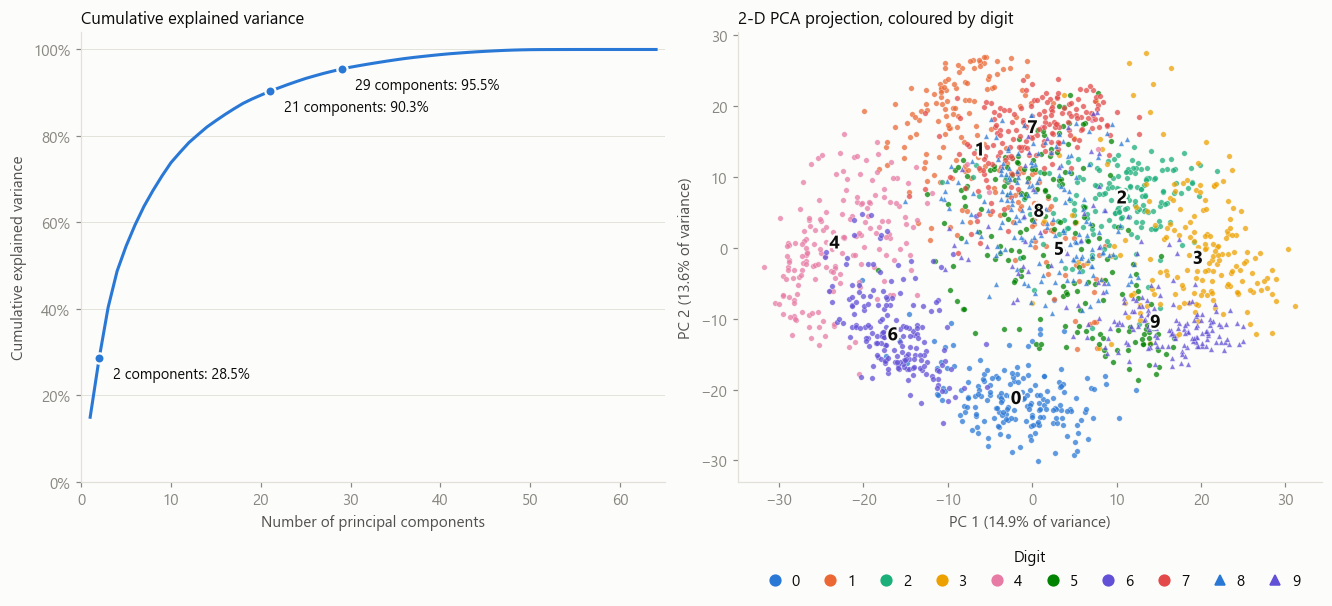

In [ ]:
ratio = ours["explained_variance_ratio"]
cumulative = np.cumsum(ratio)
Z_pca = ours["scores"][:, :2]
k_marks = [2, int(np.searchsorted(cumulative, 0.90) + 1), int(np.searchsorted(cumulative, 0.95) + 1)]

fig, (ax_var, ax_pca) = plt.subplots(1, 2, figsize=(12, 5.4), layout="constrained")

ks = np.arange(1, len(cumulative) + 1)
ax_var.plot(ks, cumulative, color=BLUE, linewidth=2)
ax_var.scatter([k for k in k_marks], cumulative[np.array(k_marks) - 1], s=45, color=BLUE,
               edgecolors=SURFACE, linewidths=1.5, zorder=3)
for k in k_marks:
    ax_var.annotate(f"{k} components: {cumulative[k - 1]:.1%}", (k, cumulative[k - 1]),
                    xytext=(9, -13), textcoords="offset points", color=INK, fontsize=9.5)
ax_var.set(xlabel="Number of principal components", ylabel="Cumulative explained variance", ylim=(0, 1.04), xlim=(0, 65))
ax_var.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_var.grid(axis="y")
ax_var.set_axisbelow(True)
ax_var.set_title("Cumulative explained variance", loc="left")

scatter_by_class(ax_pca, Z_pca, y, "2-D PCA projection, coloured by digit")
ax_pca.set(xlabel=f"PC 1 ({ratio[0]:.1%} of variance)", ylabel=f"PC 2 ({ratio[1]:.1%} of variance)")
ax_pca.legend(handles=class_handles(), title="Digit", ncol=10, loc="upper center", bbox_to_anchor=(0.5, -0.12),
              handletextpad=0.1, columnspacing=1.0)
plt.show()

## Problem 7 [Python]: PCA, t-SNE and UMAP side by side

All three methods use the same 64-dimensional pixel features. t-SNE and UMAP use their common defaults (t-SNE: perplexity 30, PCA initialisation; UMAP: 15 neighbours, `min_dist=0.1`) with a fixed seed. The t-SNE and UMAP axes have no tick labels because their coordinates have no units of their own.

C:\Users\Komputer\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Nie można odnaleźć określonego pliku
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Komputer\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Komputer\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Komputer\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_

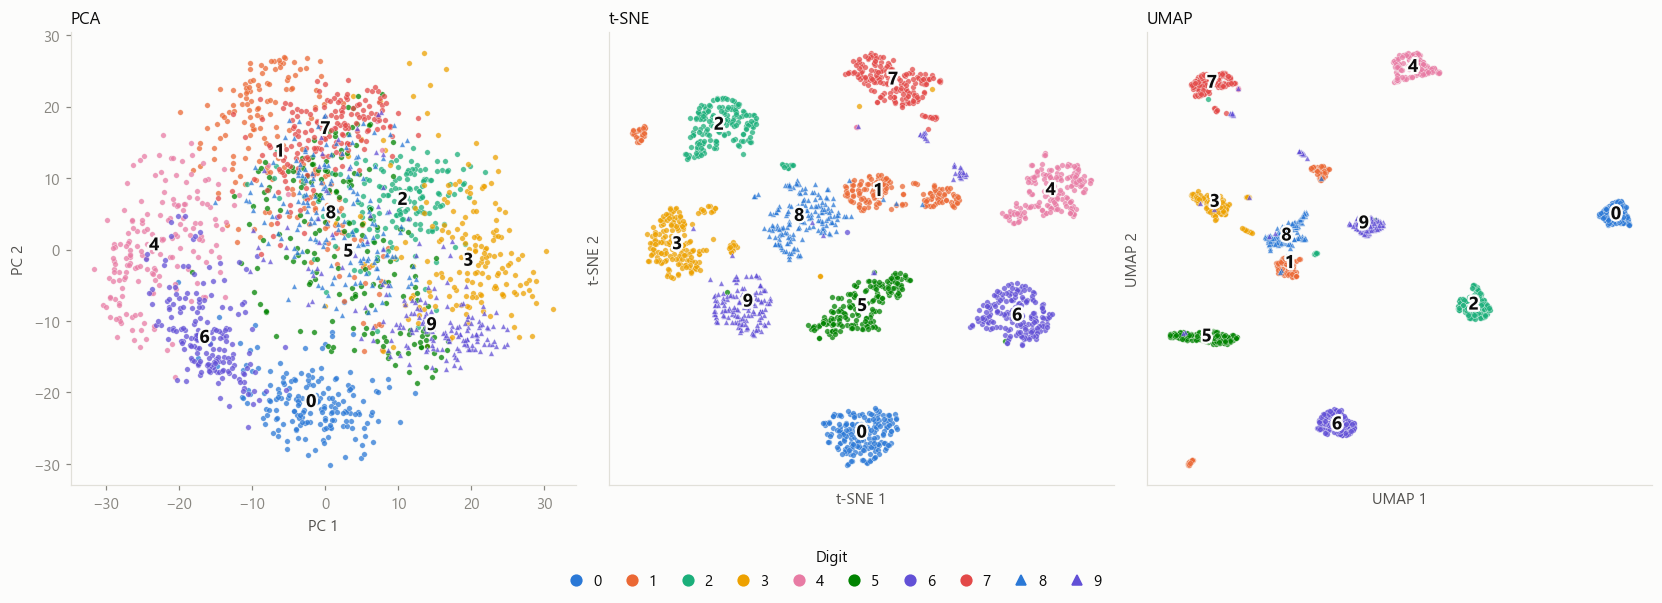

In [ ]:
Z_tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(X)
Z_umap = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED, n_jobs=1).fit_transform(X)

embeddings = {"PCA": Z_pca, "t-SNE": Z_tsne, "UMAP": Z_umap}

fig, axes = plt.subplots(1, 3, figsize=(15, 5.4), layout="constrained")
for ax, (name, Z) in zip(axes, embeddings.items()):
    scatter_by_class(ax, Z, y, name, ticks=name == "PCA")
axes[0].set(xlabel="PC 1", ylabel="PC 2")
axes[1].set(xlabel="t-SNE 1", ylabel="t-SNE 2")
axes[2].set(xlabel="UMAP 1", ylabel="UMAP 2")
fig.legend(handles=class_handles(), title="Digit", ncol=10, loc="outside lower center", handletextpad=0.1, columnspacing=1.0)
plt.show()

## Problem 8 [Analysis]: Comparing the embeddings

To support the discussion with numbers, the next cell measures three things for each embedding:

- **Trustworthiness** ($k=15$): how far the 2-D neighbours are true neighbours in 64-D. It measures local structure, and 1 is best.
- **Pairwise distance correlation:** the Spearman correlation between all point-to-point distances in 64-D and in 2-D. It measures global structure.
- **Class-centroid correlation:** the same correlation for the 45 distances between digit-class centroids. It measures large-scale arrangement of the classes.

An extra t-SNE run with random initialisation shows how much of its large-scale layout comes from the PCA starting point.

In [ ]:
D_high = pdist(X)


def centroids(Z):
    return np.vstack([Z[y == digit].mean(axis=0) for digit in np.unique(y)])


centroid_high = pdist(centroids(X))
Z_tsne_random = TSNE(n_components=2, perplexity=30, init="random", learning_rate="auto", random_state=SEED).fit_transform(X)

scores = pd.DataFrame({
    name: {
        "trustworthiness (k=15)": trustworthiness(X, Z, n_neighbors=15),
        "pairwise distance Spearman": spearmanr(D_high, pdist(Z)).statistic,
        "class-centroid distance Spearman": spearmanr(centroid_high, pdist(centroids(Z))).statistic,
    }
    for name, Z in {**embeddings, "t-SNE (random init)": Z_tsne_random}.items()
}).T.round(3)
display(scores)


def relative_contrast(A):
    D = squareform(pdist(A))
    np.fill_diagonal(D, np.inf)
    d_min = D.min(axis=1)
    np.fill_diagonal(D, 0)
    d_max = D.max(axis=1)
    keep = d_min > 0
    return ((d_max - d_min)[keep] / d_min[keep]).mean()


uniform_64 = np.random.default_rng(SEED).random(X.shape)
print(f"Mean (D_max - D_min) / D_min per point: digits {relative_contrast(X):.2f}, uniform in [0,1]^64 {relative_contrast(uniform_64):.2f}")

,trustworthiness (k=15),pairwise distance Spearman,class-centroid distance Spearman
PCA,0.829,0.582,0.815
t-SNE,0.990,0.505,0.816
UMAP,0.987,0.357,0.518
t-SNE (random init),0.991,0.460,0.758


Mean (D_max - D_min) / D_min per point: digits 3.25, uniform in [0,1]^64 0.62


### Which method preserves what?

| | Trustworthiness (local) | All pairwise distances (global) | Class centroids (large scale) |
|---|---|---|---|
| **PCA** | 0.829 | **0.582** | 0.815 |
| **t-SNE** (PCA init) | **0.990** | 0.505 | 0.816 |
| **t-SNE** (random init) | 0.991 | 0.460 | 0.758 |
| **UMAP** | 0.987 | 0.357 | 0.518 |

**Global distances: PCA.** It has the highest correlation over all point pairs. PCA is an orthogonal linear projection, so a single linear map applies to every pair, and $\lVert W^\top(x-y)\rVert\le\lVert x-y\rVert$ always holds. By Problem 4 it keeps the directions of maximum variance, and those are dominated by the large between-point differences. Its limitation is visible in the figure: two components retain only 28.5% of the variance, so classes that differ along the other 62 directions overlap (for example 1, 5, 7 and 8 in the middle of the plot).

At the level of class centroids, t-SNE with PCA initialisation matches PCA (0.816 vs 0.815). That is largely inherited from its starting point: with random initialisation the value falls to 0.758 and the all-pairs correlation falls to 0.460. The t-SNE objective itself does not target global structure.

**Local neighbourhoods: t-SNE and UMAP.** Both reach a trustworthiness near 0.99, compared with 0.83 for PCA, and they separate the digit classes clearly. Their objectives are defined on neighbour relations. The t-SNE KL divergence is heavily penalised when true neighbours are placed far apart, but barely penalised for how far apart non-neighbours end up. UMAP fits a sparse $k$-nearest-neighbour graph with a cross-entropy loss, whose repulsive term pushes non-neighbours apart without calibrating by how much. UMAP scores lowest on both global measures here.

### Why t-SNE/UMAP distances cannot be read as similarities

1. **Each point measures closeness on its own scale.** Before placing points on the plot, t-SNE and UMAP decide separately for every point how far away another point can be and still count as "close". In crowded regions this limit is small, while in sparse regions it is large. As a result, the same distance in the original 64-D space can count as "very close" for one point and "far" for another, so there is no common ruler that converts distances on the plot back into distances in the original data. A side effect is that groups tend to come out at similar sizes on the plot, so a large or small cluster on the plot says little about how spread out that class really is in 64-D.

2. **Long distances are not fitted.** Only neighbour relations are constrained, so the gap between two clusters is determined by the balance of attractive and repulsive forces, not by how different the clusters are. t-SNE's heavy-tailed kernel also deliberately stretches moderate distances. In the figure, digit 1 splits into several islands that sit far apart in t-SNE and UMAP, even though they belong to one class, and the empty space between them has no quantitative meaning.
3. **The layout is not unique.** It depends on the seed, the initialisation, the perplexity or `n_neighbors`, and `min_dist`, which directly controls how tightly UMAP packs its clusters. The t-SNE random-initialisation row above shows this sensitivity. Only "these points are neighbours" is reasonably stable.

### Relation to Problems 1–3

- **Problem 1.** Neighbour-based methods depend on *rankings*. On unit-normalised data, Euclidean and cosine distance give the same neighbour lists, so the choice between them could only change the weights, not who counts as a neighbour. The digit vectors here are not normalised, so that equivalence does not apply directly to this run.
- **Problem 2.** The cosine-distance counterexample shows that a numerical dissimilarity need not combine like a distance. The same caution applies here. A 2-D plot does obey the triangle inequality, but only as a property of the plane. The locally rescaled quantities used in fitting are not symmetric until they are explicitly symmetrised, and they do not define a metric on the data. Adding or comparing distances read from the plot therefore tells us nothing reliable about 64-D geometry.
- **Problem 3.** Under distance concentration, raw distance values carry little information, so these methods rely on local ranks and adaptive scales instead. Concentration also explains why the methods work here at all: digits have a mean relative contrast of 3.25, against 0.62 for uniform data of the same size and dimension, and 21 principal components already hold 90% of the variance. The data are effectively low-dimensional, so neighbours are meaningful. The shell argument explains *crowding*: in high dimensions many points can lie at similar moderate distances from a point, but a 2-D neighbourhood has too little room for them, because the area available at radius $r$ grows only linearly in $r$. Pushing those points outwards inflates moderate distances, which is another reason why 2-D gaps are not proportional to real dissimilarity.

**Conclusion.** PCA is the appropriate tool for reading large-scale structure and for an interpretable linear map, with the caveat that it shows only the variance it retains. t-SNE and UMAP are appropriate for discovering local groups. Claims about how far apart clusters are should be checked in the original space, not read from the t-SNE or UMAP plot.